# Handwritten Digit Recognition using MNIST dataset

## Import the required Libraries

In [1]:
# import all required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import plot_model

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

## Load MNIST dataset

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = mnist.load_data()

print("Original training set shape:", X_train_full.shape, y_train_full.shape)
print("Original test set shape:", X_test.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original training set shape: (60000, 28, 28) (60000,)
Original test set shape: (10000, 28, 28) (10000,)


## Data visualization

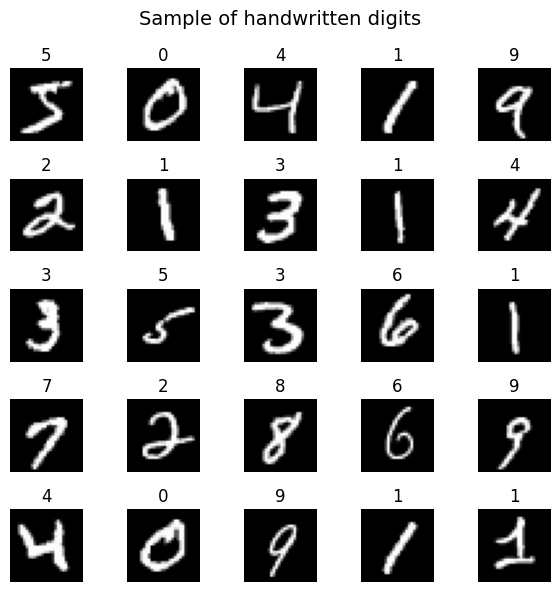

In [3]:
plt.figure(figsize=(6, 6))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_full[i], cmap='gray')
    plt.title(y_train_full[i])
    plt.axis('off')

plt.suptitle("Sample of handwritten digits", fontsize=14)
plt.tight_layout()
plt.show()

To understand the dataset, we visualize several handwritten digit samples from the MNIST dataset. The images show that the same digit can be written in many different styles by different people. For example, the digit "1" may appear with different shapes, thickness, or orientation. This variation makes digit recognition a challenging classification problem.

## Class distribution

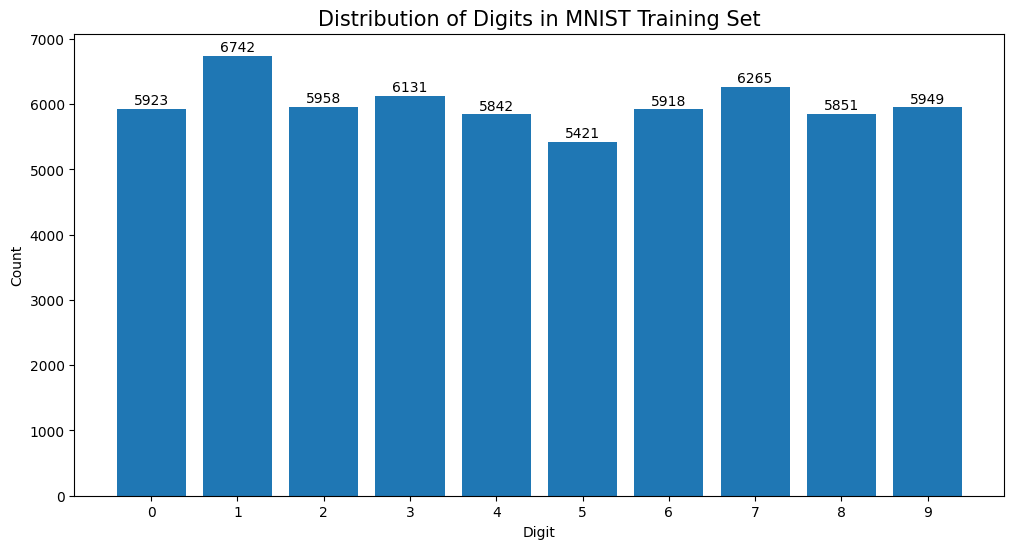

In [4]:
digit_counts = Counter(y_train_full)

digits = list(range(10))
counts = [digit_counts[d] for d in digits]

plt.figure(figsize=(12, 6))
bars = plt.bar(digits, counts)

plt.title("Distribution of Digits in MNIST Training Set", fontsize=15)
plt.xlabel("Digit")
plt.ylabel("Count")
plt.xticks(digits)

# Put count values on top of each bar
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
             str(count), ha='center', va='bottom', fontsize=10)

plt.show()

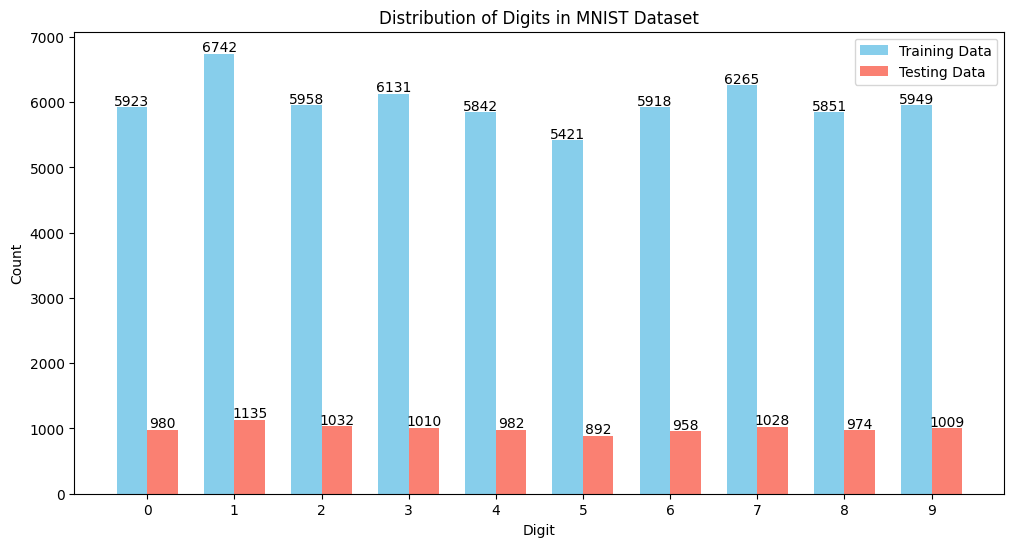

In [5]:
# Count digits
train_counts = Counter(y_train_full)
test_counts = Counter(y_test)

digits = np.arange(10)

train_values = [train_counts[d] for d in digits]
test_values = [test_counts[d] for d in digits]

# bar width
width = 0.35

plt.figure(figsize=(12,6))

# training bars
plt.bar(digits - width/2, train_values, width=width, label="Training Data", color='skyblue')

# testing bars
plt.bar(digits + width/2, test_values, width=width, label="Testing Data", color='salmon')

plt.xlabel("Digit")
plt.ylabel("Count")
plt.title("Distribution of Digits in MNIST Dataset")
plt.xticks(digits)
plt.legend()

# add values above bars
for i in range(len(digits)):
    plt.text(digits[i] - width/2, train_values[i] + 30, str(train_values[i]),
             ha='center', fontsize=10)

    plt.text(digits[i] + width/2, test_values[i] + 30, str(test_values[i]),
             ha='center', fontsize=10)

plt.show()

## Normalize images

In [6]:
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Pixel range after normalization:")
print("Train min:", X_train_full.min(), "Train max:", X_train_full.max())
print("Test min:", X_test.min(), "Test max:", X_test.max())

Pixel range after normalization:
Train min: 0.0 Train max: 1.0
Test min: 0.0 Test max: 1.0


## Split training data into train and validation

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("Train set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Train set: (48000, 28, 28) (48000,)
Validation set: (12000, 28, 28) (12000,)
Test set: (10000, 28, 28) (10000,)


## Data Preparation

In [8]:
# Flat format for KNN / SVM / MLP
X_train_flat = X_train.reshape(-1, 28*28)
X_val_flat   = X_val.reshape(-1, 28*28)
X_test_flat  = X_test.reshape(-1, 28*28)

print("Flat train shape:", X_train_flat.shape)
print("Flat val shape:", X_val_flat.shape)
print("Flat test shape:", X_test_flat.shape)

# CNN format
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_val_cnn   = X_val.reshape(-1, 28, 28, 1)
X_test_cnn  = X_test.reshape(-1, 28, 28, 1)

print("\nCNN train shape:", X_train_cnn.shape)
print("CNN val shape:", X_val_cnn.shape)
print("CNN test shape:", X_test_cnn.shape)

# One-hot labels for CNN
y_train_onehot = to_categorical(y_train, 10)
y_val_onehot   = to_categorical(y_val, 10)
y_test_onehot  = to_categorical(y_test, 10)

print("\ny_train_onehot:", y_train_onehot.shape)
print("y_val_onehot:", y_val_onehot.shape)
print("y_test_onehot:", y_test_onehot.shape)

Flat train shape: (48000, 784)
Flat val shape: (12000, 784)
Flat test shape: (10000, 784)

CNN train shape: (48000, 28, 28, 1)
CNN val shape: (12000, 28, 28, 1)
CNN test shape: (10000, 28, 28, 1)

y_train_onehot: (48000, 10)
y_val_onehot: (12000, 10)
y_test_onehot: (10000, 10)


## Helper Functions for Evaluation

In [9]:
def evaluate_model(y_true, y_pred, model_name="Model"):
    print(f"\n===== {model_name} Classification Report =====")
    print(classification_report(y_true, y_pred, digits=4))

    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted'
    )

    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }


def plot_conf_matrix(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

## Traditional Machine learning models

### KNN Model


===== KNN Classification Report =====
              precision    recall  f1-score   support

           0     0.9634    0.9929    0.9779       980
           1     0.9521    0.9974    0.9742      1135
           2     0.9813    0.9641    0.9726      1032
           3     0.9616    0.9673    0.9645      1010
           4     0.9772    0.9613    0.9692       982
           5     0.9640    0.9596    0.9618       892
           6     0.9812    0.9823    0.9817       958
           7     0.9629    0.9601    0.9615      1028
           8     0.9881    0.9353    0.9610       974
           9     0.9585    0.9604    0.9594      1009

    accuracy                         0.9685     10000
   macro avg     0.9690    0.9681    0.9684     10000
weighted avg     0.9687    0.9685    0.9685     10000



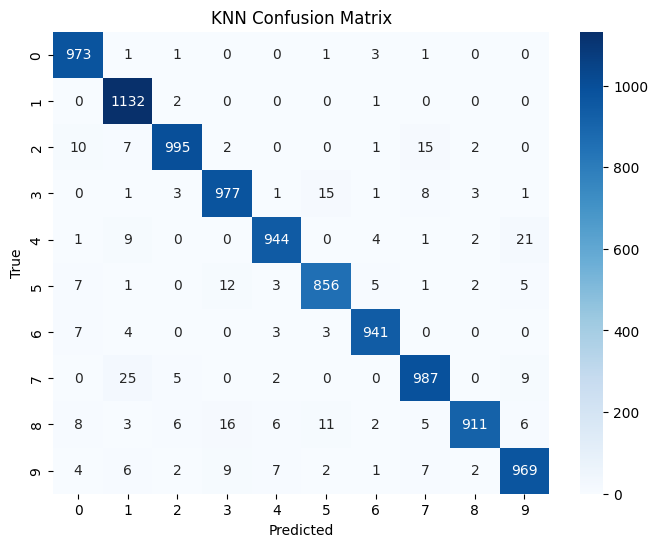

In [10]:
knn_model = KNeighborsClassifier(n_neighbors=3)

knn_model.fit(X_train_flat, y_train)

y_val_pred_knn = knn_model.predict(X_val_flat)
y_test_pred_knn = knn_model.predict(X_test_flat)

knn_results = evaluate_model(y_test, y_test_pred_knn, "KNN")
plot_conf_matrix(y_test, y_test_pred_knn, "KNN Confusion Matrix")

### KNN nearest neighbors for a few test samples

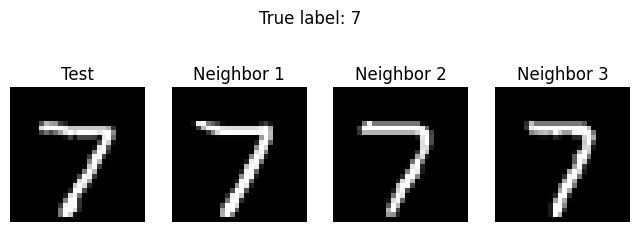

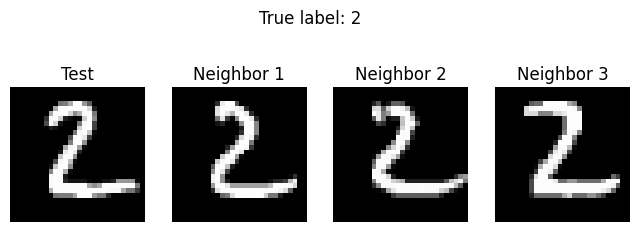

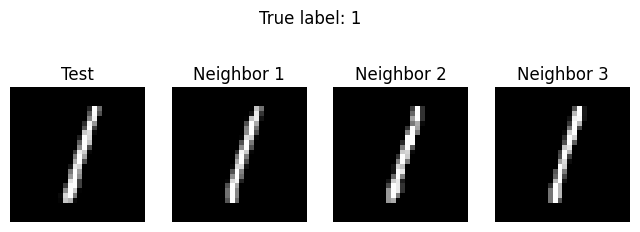

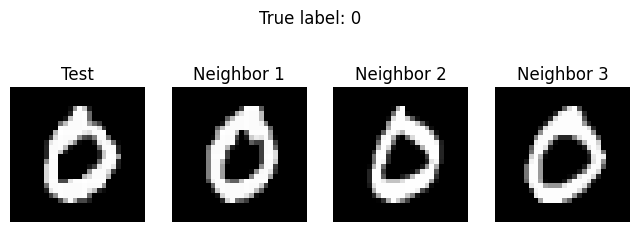

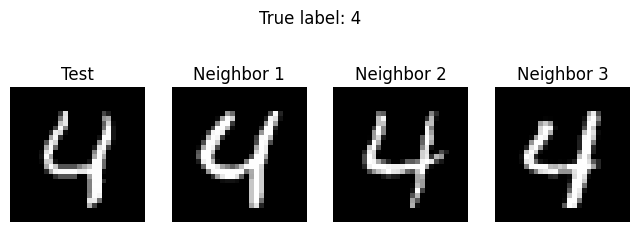

In [11]:
num_examples = 5   # number of test images to visualize

for test_index in range(num_examples):

    distances, indices = knn_model.kneighbors(
        X_test_flat[test_index].reshape(1, -1),
        n_neighbors=3
    )

    plt.figure(figsize=(8,3))

    # Show test image
    plt.subplot(1,4,1)
    plt.imshow(X_test[test_index], cmap='gray')
    plt.title("Test")
    plt.axis("off")

    # Show nearest neighbors
    for i in range(3):
        plt.subplot(1,4,i+2)
        plt.imshow(X_train[indices[0][i]], cmap='gray')
        plt.title(f"Neighbor {i+1}")
        plt.axis("off")

    plt.suptitle(f"True label: {y_test[test_index]}")
    plt.show()

### SVM Model


===== SVM Classification Report =====
              precision    recall  f1-score   support

           0     0.9789    0.9929    0.9858       980
           1     0.9860    0.9921    0.9890      1135
           2     0.9739    0.9758    0.9748      1032
           3     0.9735    0.9832    0.9783      1010
           4     0.9806    0.9756    0.9781       982
           5     0.9842    0.9753    0.9797       892
           6     0.9874    0.9833    0.9854       958
           7     0.9735    0.9630    0.9682      1028
           8     0.9704    0.9754    0.9729       974
           9     0.9680    0.9584    0.9631      1009

    accuracy                         0.9776     10000
   macro avg     0.9776    0.9775    0.9775     10000
weighted avg     0.9776    0.9776    0.9776     10000



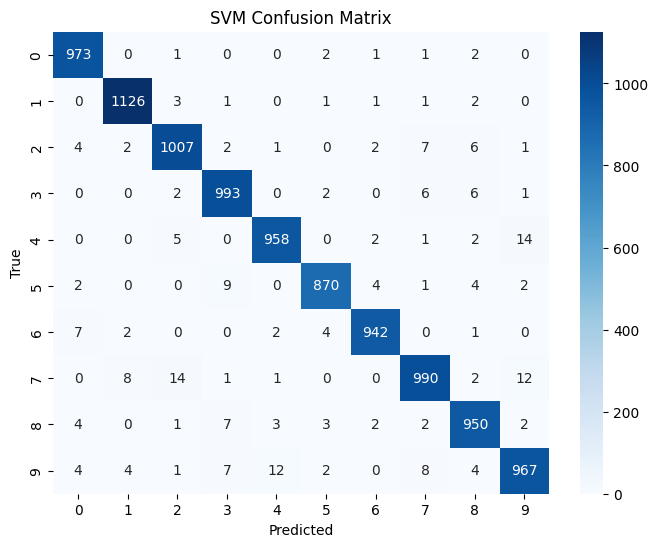

In [12]:
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale')

svm_model.fit(X_train_flat, y_train)

y_val_pred_svm = svm_model.predict(X_val_flat)
y_test_pred_svm = svm_model.predict(X_test_flat)

svm_results = evaluate_model(y_test, y_test_pred_svm, "SVM")
plot_conf_matrix(y_test, y_test_pred_svm, "SVM Confusion Matrix")

## Deep learning models

### Multilayer Perceptron (MLP) Model

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7599 - loss: 0.7626 - val_accuracy: 0.9500 - val_loss: 0.1649
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9446 - loss: 0.1906 - val_accuracy: 0.9637 - val_loss: 0.1187
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9584 - loss: 0.1380 - val_accuracy: 0.9692 - val_loss: 0.0987
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9684 - loss: 0.1056 - val_accuracy: 0.9746 - val_loss: 0.0884
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9726 - loss: 0.0912 - val_accuracy: 0.9741 - val_loss: 0.0840
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9756 - loss: 0.0788 - val_accuracy: 0.9765 - val_loss: 0.0794
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9778 - loss: 0.0720 - val_accuracy: 0.9785 - val_loss: 0.0726
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9786 - loss: 0.0653 - val_accuracy: 0.

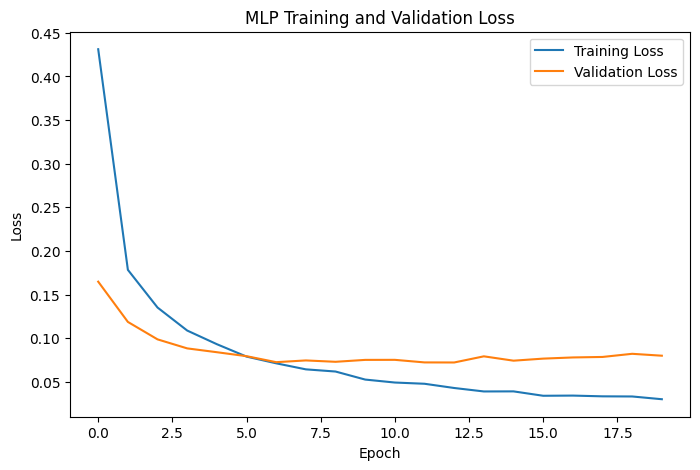

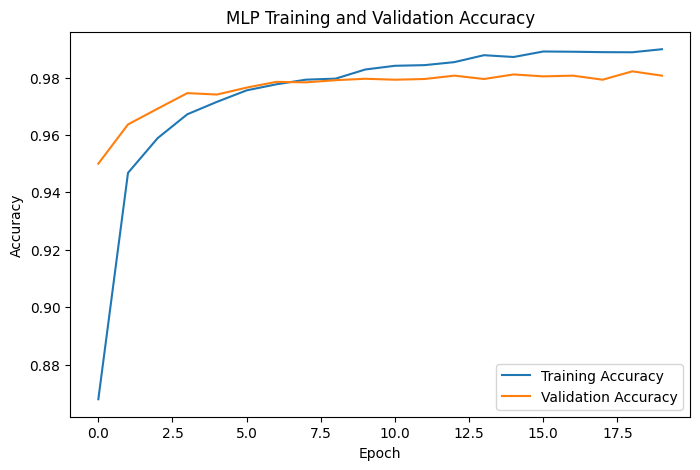

In [13]:
mlp_model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

mlp_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

mlp_history = mlp_model.fit(
    X_train_flat, y_train_onehot,
    validation_data=(X_val_flat, y_val_onehot),
    epochs=20,
    batch_size=128,
    verbose=1
)

# Plot MLP Training and Validation Loss
plt.figure(figsize=(8,5))
plt.plot(mlp_history.history['loss'], label='Training Loss')
plt.plot(mlp_history.history['val_loss'], label='Validation Loss')
plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Plot MLP Training and Validation Accuracy
plt.figure(figsize=(8,5))

plt.plot(mlp_history.history['accuracy'], label='Training Accuracy')
plt.plot(mlp_history.history['val_accuracy'], label='Validation Accuracy')

plt.title("MLP Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

In [14]:
!apt-get install graphviz -y
!pip install pydot

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-6ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 37 not upgraded.


In [15]:
# Show model summary
mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

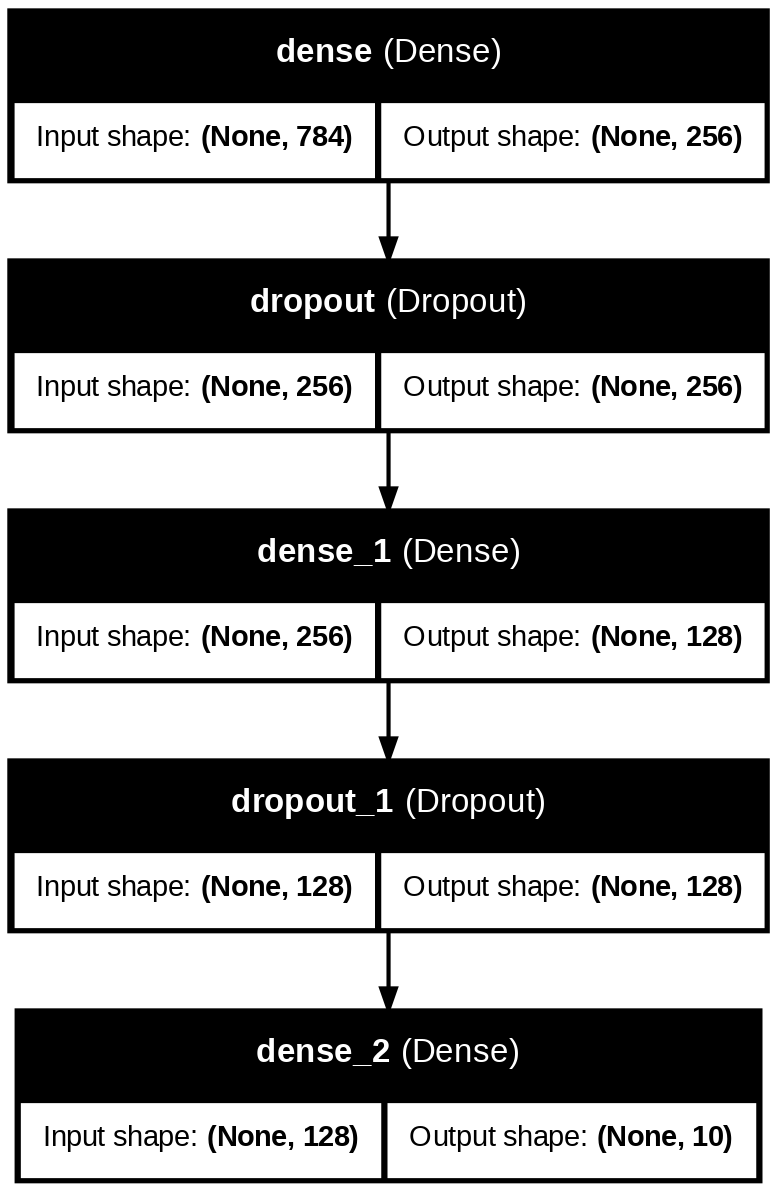

In [16]:
# Import for displaying image
from IPython.display import Image, display

# Save architecture diagram
plot_model(
    mlp_model,
    to_file="mlp_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=150
)

# Display architecture diagram
display(Image("mlp_architecture.png"))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

===== MLP Classification Report =====
              precision    recall  f1-score   support

           0     0.9789    0.9918    0.9853       980
           1     0.9877    0.9912    0.9894      1135
           2     0.9854    0.9777    0.9815      1032
           3     0.9689    0.9861    0.9774      1010
           4     0.9825    0.9735    0.9780       982
           5     0.9765    0.9787    0.9776       892
           6     0.9812    0.9802    0.9807       958
           7     0.9796    0.9815    0.9806      1028
           8     0.9822    0.9641    0.9731       974
           9     0.9742    0.9713    0.9727      1009

    accuracy                         0.9798     10000
   macro avg     0.9797    0.9796    0.9796     10000
weighted avg     0.9798    0.9798    0.9798     10000



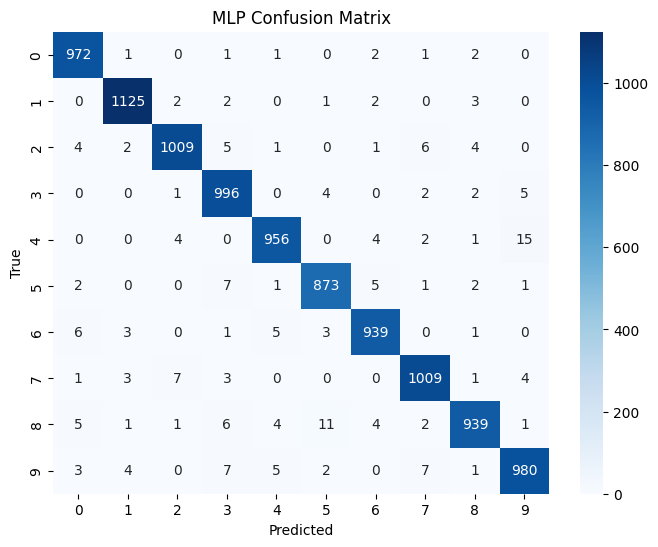

In [17]:
# TEST MLP
y_test_pred_mlp = np.argmax(mlp_model.predict(X_test_flat), axis=1)

mlp_results = evaluate_model(y_test, y_test_pred_mlp, "MLP")
plot_conf_matrix(y_test, y_test_pred_mlp, "MLP Confusion Matrix")

### CNN Model

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.7680 - loss: 0.7312 - val_accuracy: 0.9760 - val_loss: 0.0791
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9634 - loss: 0.1208 - val_accuracy: 0.9837 - val_loss: 0.0573
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9756 - loss: 0.0831 - val_accuracy: 0.9804 - val_loss: 0.0598
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9800 - loss: 0.0704 - val_accuracy: 0.9852 - val_loss: 0.0492
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9829 - loss: 0.0588 - val_accuracy: 0.9870 - val_loss: 0.0416
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9848 - loss: 0.0502 - val_accuracy: 0.9883 - val_loss: 0.0426
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9860 - loss: 0.0433 - val_accuracy: 0.9887 - val_loss: 0.0412
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9887 - loss: 0.0364 - val_accuracy: 

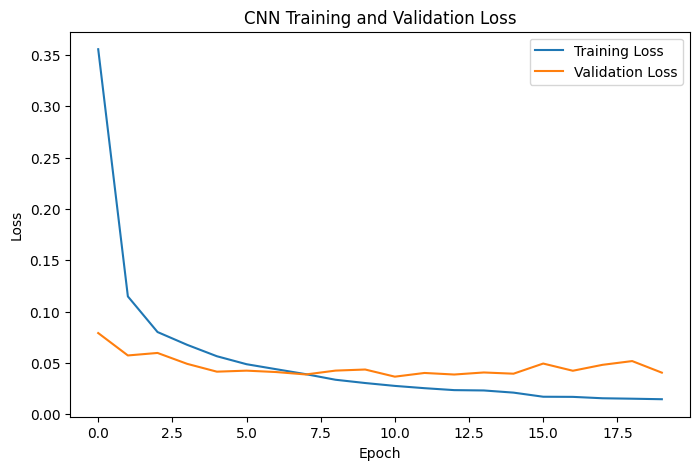

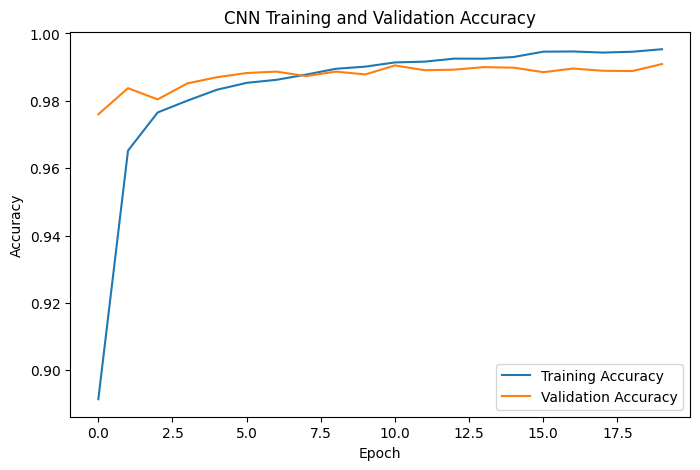

In [18]:
cnn_model = Sequential([
    Input(shape=(28,28,1)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_history = cnn_model.fit(
    X_train_cnn, y_train_onehot,
    validation_data=(X_val_cnn, y_val_onehot),
    epochs=20,
    batch_size=128,
    verbose=1
)

# Plot CNN Loss
plt.figure(figsize=(8,5))
plt.plot(cnn_history.history['loss'], label='Training Loss')
plt.plot(cnn_history.history['val_loss'], label='Validation Loss')
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Plot CNN Training and Validation Accuracy
plt.figure(figsize=(8,5))

plt.plot(cnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

In [19]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,104 (2.58 MB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 450,070 (1.72 MB)

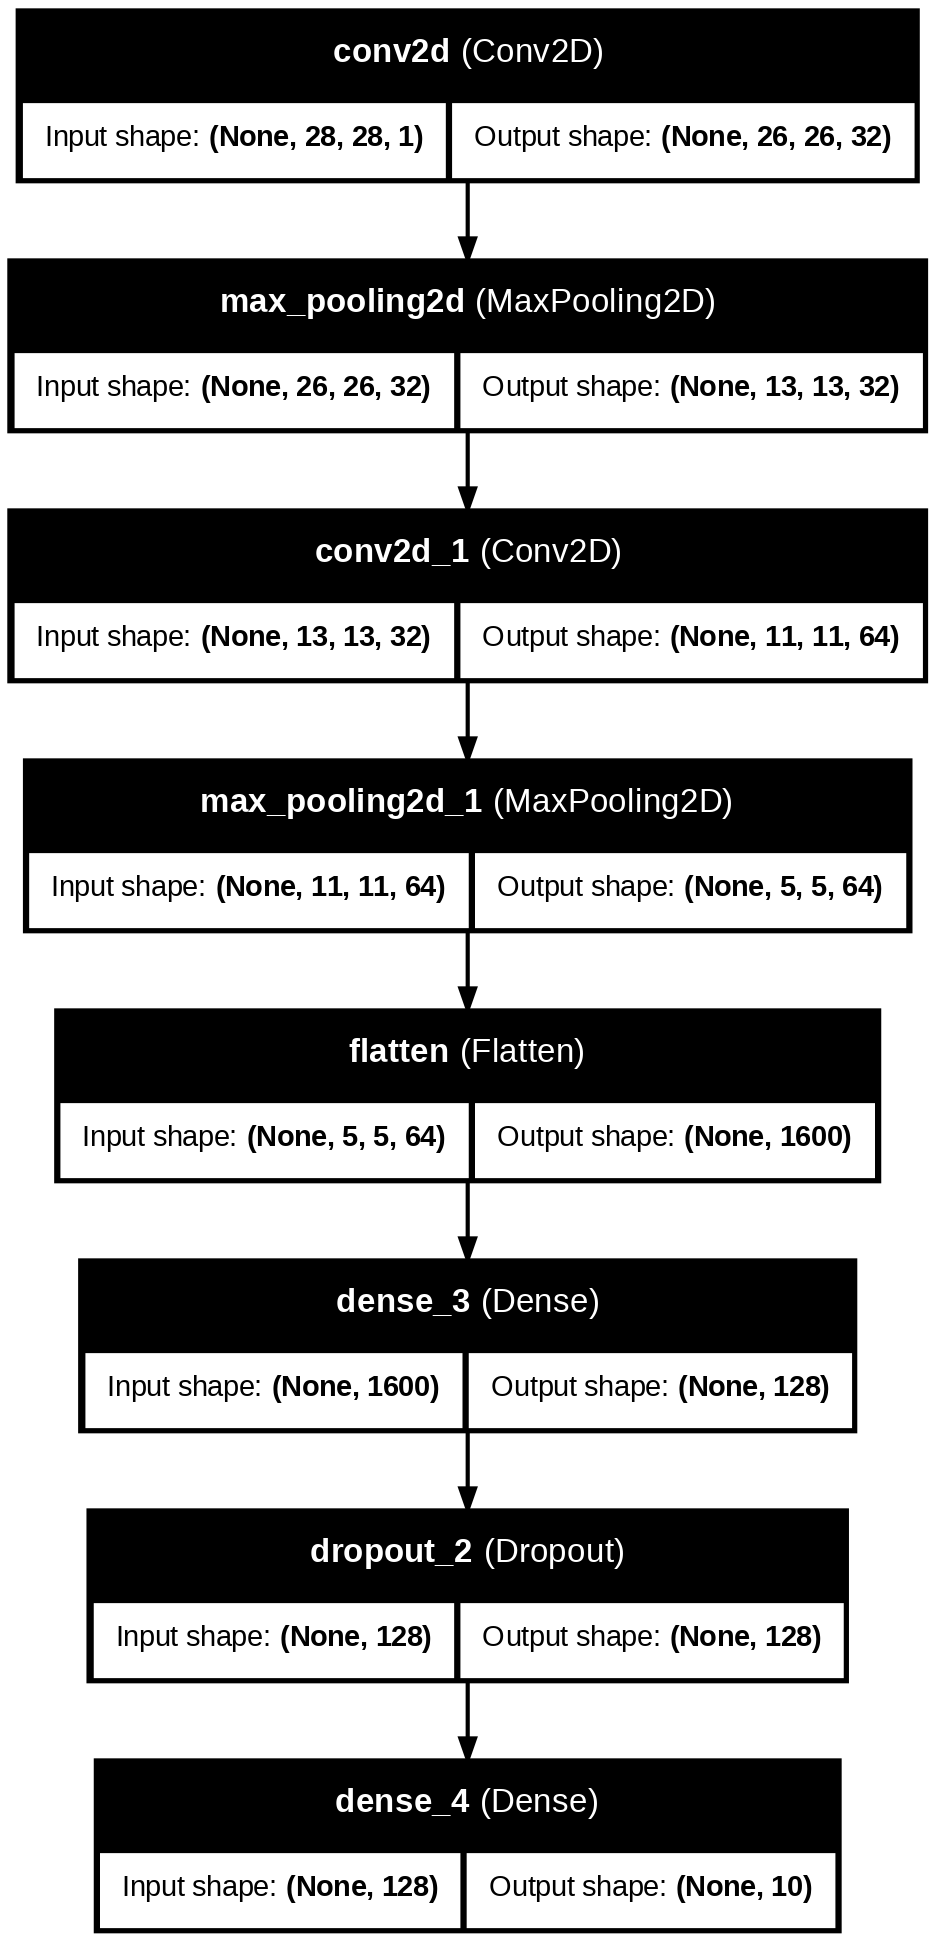

In [20]:
# Save CNN architecture diagram
plot_model(
    cnn_model,
    to_file="cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=150
)

# Display architecture diagram
display(Image("cnn_architecture.png"))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

===== CNN Classification Report =====
              precision    recall  f1-score   support

           0     0.9909    0.9990    0.9949       980
           1     0.9965    0.9991    0.9978      1135
           2     0.9932    0.9903    0.9918      1032
           3     0.9950    0.9941    0.9946      1010
           4     0.9909    0.9969    0.9939       982
           5     0.9899    0.9910    0.9905       892
           6     0.9989    0.9906    0.9948       958
           7     0.9836    0.9942    0.9889      1028
           8     0.9959    0.9877    0.9918       974
           9     0.9920    0.9832    0.9876      1009

    accuracy                         0.9927     10000
   macro avg     0.9927    0.9926    0.9926     10000
weighted avg     0.9927    0.9927    0.9927     10000



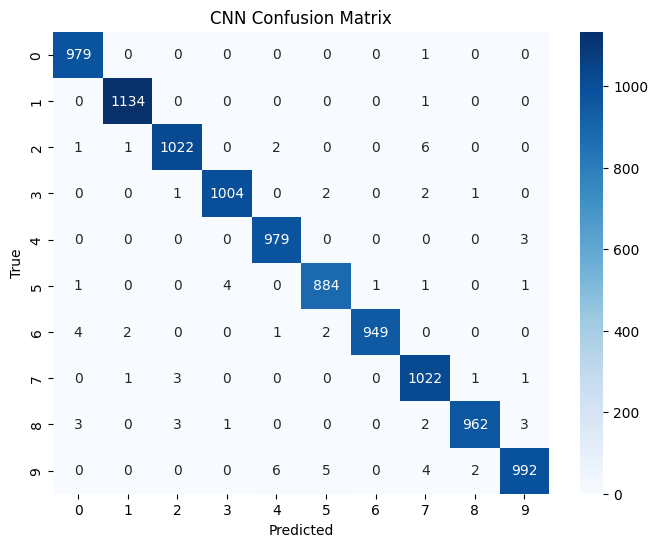

In [21]:
# TEST CNN
y_test_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=1)

cnn_results = evaluate_model(y_test, y_test_pred_cnn, "CNN")
plot_conf_matrix(y_test, y_test_pred_cnn, "CNN Confusion Matrix")

## Hybrid Model

### CNN-SVM

In [22]:
# CNN feature extractor for CNN-SVM

cnn_svm_base_input = Input(shape=(28, 28, 1))

x = Conv2D(32, (3, 3), activation='relu')(cnn_svm_base_input)
x = MaxPooling2D((2, 2))(x)

x = Conv2D(64, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)

x = Flatten()(x)
feature_layer = Dense(128, activation='relu', name='feature_layer')(x)
x = Dropout(0.5)(feature_layer)
output_layer = Dense(10, activation='softmax')(x)

cnn_svm_base_model = Model(inputs=cnn_svm_base_input, outputs=output_layer)

cnn_svm_base_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_svm_base_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_layer (Dense)           │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7810 - loss: 0.6894 - val_accuracy: 0.9745 - val_loss: 0.0796
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9651 - loss: 0.1143 - val_accuracy: 0.9827 - val_loss: 0.0546
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9754 - loss: 0.0788 - val_accuracy: 0.9862 - val_loss: 0.0482
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9806 - loss: 0.0633 - val_accuracy: 0.9872 - val_loss: 0.0444
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9841 - loss: 0.0526 - val_accuracy: 0.9871 - val_loss: 0.0413
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9856 - loss: 0.0461 - val_accuracy: 0.9877 - val_loss: 0.0419
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9870 - loss: 0.0425 - val_accuracy: 0.9887 - val_loss: 0.0422
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9879 - loss: 0.0367 - val_accuracy: 0.

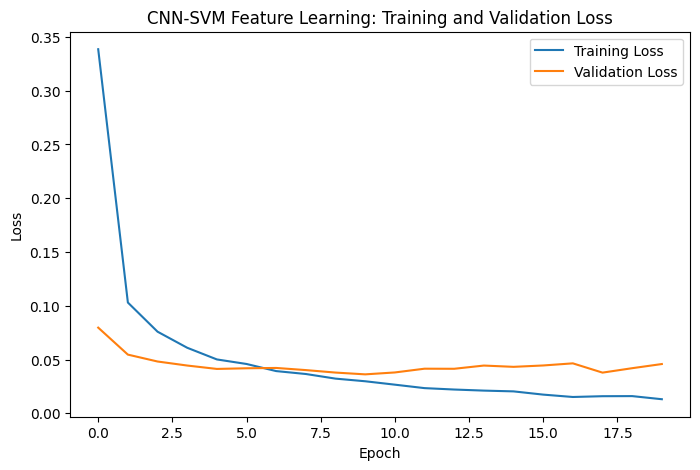

In [23]:
# Train SVM on CNN Features

cnn_svm_history = cnn_svm_base_model.fit(
    X_train_cnn, y_train_onehot,
    validation_data=(X_val_cnn, y_val_onehot),
    epochs=20,
    batch_size=128,
    verbose=1
)

# Plot training and validation loss
plt.figure(figsize=(8,5))
plt.plot(cnn_svm_history.history['loss'], label='Training Loss')
plt.plot(cnn_svm_history.history['val_loss'], label='Validation Loss')
plt.title("CNN-SVM Feature Learning: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [24]:
# Create feature extractor model

feature_extractor = Model(
    inputs=cnn_svm_base_model.input,
    outputs=cnn_svm_base_model.get_layer('feature_layer').output
)

X_train_features = feature_extractor.predict(X_train_cnn)
X_val_features = feature_extractor.predict(X_val_cnn)
X_test_features = feature_extractor.predict(X_test_cnn)

print("Train feature shape:", X_train_features.shape)
print("Validation feature shape:", X_val_features.shape)
print("Test feature shape:", X_test_features.shape)

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Train feature shape: (48000, 128)
Validation feature shape: (12000, 128)
Test feature shape: (10000, 128)



===== CNN-SVM Classification Report =====
              precision    recall  f1-score   support

           0     0.9929    0.9990    0.9959       980
           1     0.9956    0.9991    0.9974      1135
           2     0.9932    0.9971    0.9952      1032
           3     0.9941    0.9941    0.9941      1010
           4     0.9939    0.9929    0.9934       982
           5     0.9888    0.9899    0.9894       892
           6     0.9958    0.9885    0.9921       958
           7     0.9942    0.9922    0.9932      1028
           8     0.9949    0.9928    0.9938       974
           9     0.9940    0.9911    0.9926      1009

    accuracy                         0.9938     10000
   macro avg     0.9937    0.9937    0.9937     10000
weighted avg     0.9938    0.9938    0.9938     10000



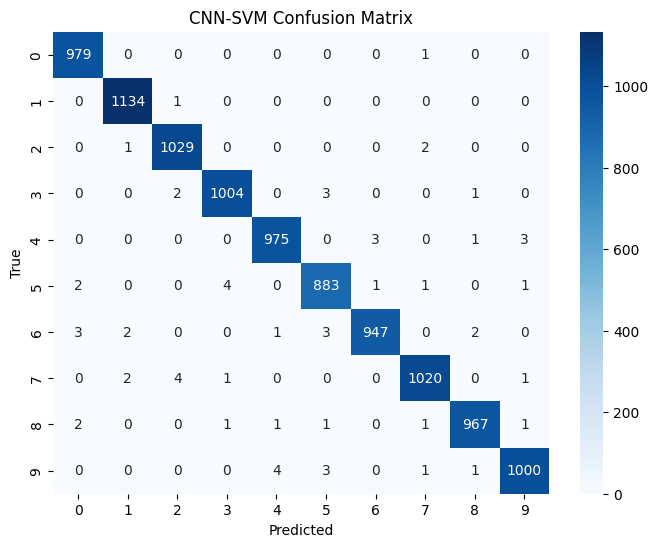

In [25]:
# Train SVM on CNN features
cnn_svm_classifier = SVC(kernel='rbf', C=2.0, gamma='scale')

cnn_svm_classifier.fit(X_train_features, y_train)

# Predict and evaluate CNN-SVM
y_val_pred_cnn_svm = cnn_svm_classifier.predict(X_val_features)
y_test_pred_cnn_svm = cnn_svm_classifier.predict(X_test_features)

cnn_svm_results = evaluate_model(y_test, y_test_pred_cnn_svm, "CNN-SVM")
plot_conf_matrix(y_test, y_test_pred_cnn_svm, "CNN-SVM Confusion Matrix")

## Model Comparison

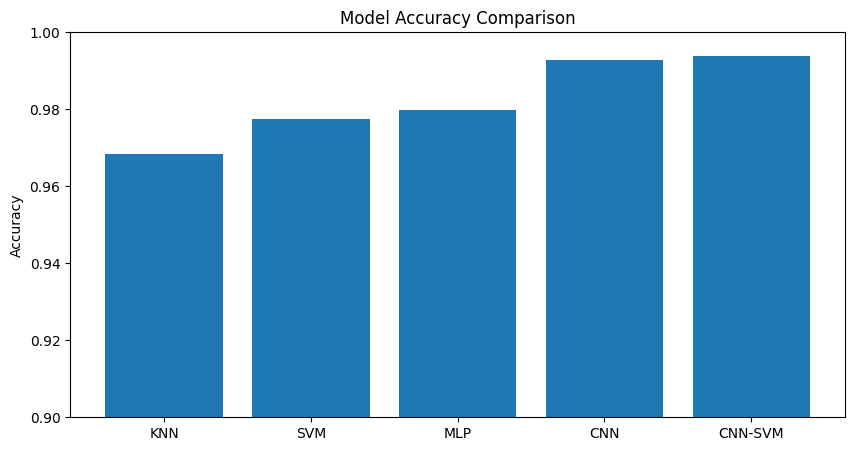

In [26]:
# Collect All Results in a Table

results_df = pd.DataFrame([
    knn_results,
    svm_results,
    mlp_results,
    cnn_results,
    cnn_svm_results
])

results_df

# Plot Accuracy Comparison
plt.figure(figsize=(10,5))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0.9, 1.0)
plt.show()

<Figure size 1000x600 with 0 Axes>

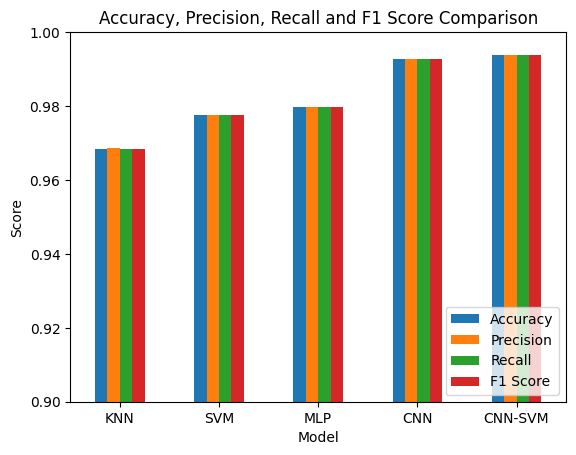

In [27]:
# Plot Precision / Recall / F1 Comparison
metrics_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]]

plt.figure(figsize=(10,6))

metrics_df.plot(kind='bar')

plt.title("Accuracy, Precision, Recall and F1 Score Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0.9, 1.0)
plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.show()

## Heatmap for Accuracy, Precision, Recall, F1 Score

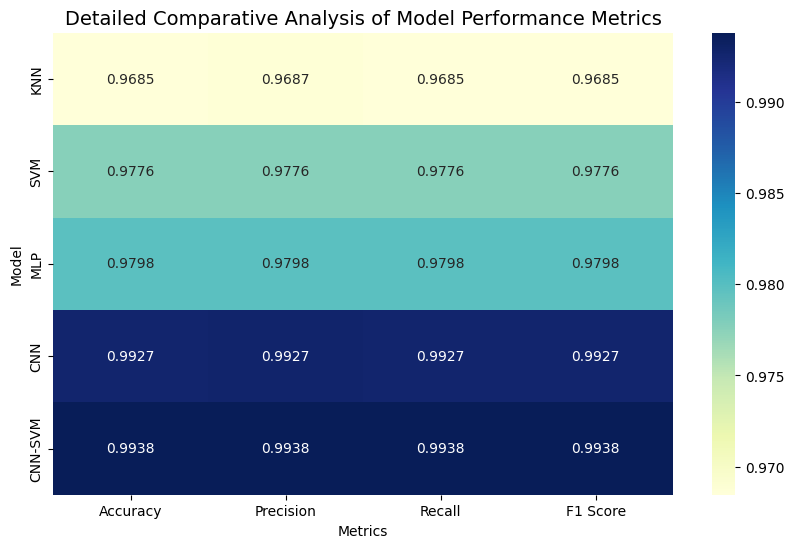

In [28]:
heatmap_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]]

plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_df,
    annot=True,          # write numbers inside boxes
    fmt=".4f",           # 4 decimal places
    cmap="YlGnBu"        # color style similar to your screenshot
)

plt.title("Detailed Comparative Analysis of Model Performance Metrics", fontsize=14)
plt.xlabel("Metrics")
plt.ylabel("Model")
plt.show()

In [29]:
# Per-Class Reports as Tables

def get_classification_report_df(y_true, y_pred):
    report = classification_report(y_true, y_pred, output_dict=True)
    return pd.DataFrame(report).transpose()

knn_report_df = get_classification_report_df(y_test, y_test_pred_knn)
svm_report_df = get_classification_report_df(y_test, y_test_pred_svm)
mlp_report_df = get_classification_report_df(y_test, y_test_pred_mlp)
cnn_report_df = get_classification_report_df(y_test, y_test_pred_cnn)
cnn_svm_report_df = get_classification_report_df(y_test, y_test_pred_cnn_svm)

print("KNN report:")
display(knn_report_df)
print("\nSVM report:")
display(svm_report_df)
print("\nMLP report:")
display(mlp_report_df)
print("\nCNN report:")
display(cnn_report_df)
print("\nCNN-SVM report:")
display(cnn_svm_report_df)

KNN report:


,precision,recall,f1-score,support
0,0.963366,0.992857,0.977889,980.0000
1,0.952061,0.997357,0.974182,1135.0000
2,0.981262,0.964147,0.972630,1032.0000
3,0.961614,0.967327,0.964462,1010.0000
4,0.977226,0.961303,0.969199,982.0000
5,0.963964,0.959641,0.961798,892.0000
6,0.981230,0.982255,0.981742,958.0000
7,0.962927,0.960117,0.961520,1028.0000
8,0.988069,0.935318,0.960970,974.0000
9,0.958457,0.960357,0.959406,1009.0000



SVM report:


,precision,recall,f1-score,support
0,0.978873,0.992857,0.985816,980.0000
1,0.985989,0.992070,0.989021,1135.0000
2,0.973888,0.975775,0.974831,1032.0000
3,0.973529,0.983168,0.978325,1010.0000
4,0.980553,0.975560,0.978050,982.0000
5,0.984163,0.975336,0.979730,892.0000
6,0.987421,0.983299,0.985356,958.0000
7,0.973451,0.963035,0.968215,1028.0000
8,0.970378,0.975359,0.972862,974.0000
9,0.967968,0.958375,0.963147,1009.0000



MLP report:


,precision,recall,f1-score,support
0,0.978852,0.991837,0.985302,980.0000
1,0.987709,0.991189,0.989446,1135.0000
2,0.985352,0.977713,0.981518,1032.0000
3,0.968872,0.986139,0.977429,1010.0000
4,0.982528,0.973523,0.978005,982.0000
5,0.976510,0.978700,0.977604,892.0000
6,0.981191,0.980167,0.980679,958.0000
7,0.979612,0.981518,0.980564,1028.0000
8,0.982218,0.964066,0.973057,974.0000
9,0.974155,0.971259,0.972705,1009.0000



CNN report:


,precision,recall,f1-score,support
0,0.990891,0.998980,0.994919,980.0000
1,0.996485,0.999119,0.997800,1135.0000
2,0.993197,0.990310,0.991752,1032.0000
3,0.995045,0.994059,0.994552,1010.0000
4,0.990891,0.996945,0.993909,982.0000
5,0.989922,0.991031,0.990476,892.0000
6,0.998947,0.990605,0.994759,958.0000
7,0.983638,0.994163,0.988873,1028.0000
8,0.995859,0.987680,0.991753,974.0000
9,0.992000,0.983152,0.987556,1009.0000



CNN-SVM report:


,precision,recall,f1-score,support
0,0.992901,0.998980,0.995931,980.0000
1,0.995610,0.999119,0.997361,1135.0000
2,0.993243,0.997093,0.995164,1032.0000
3,0.994059,0.994059,0.994059,1010.0000
4,0.993884,0.992872,0.993377,982.0000
5,0.988802,0.989910,0.989356,892.0000
6,0.995794,0.988518,0.992142,958.0000
7,0.994152,0.992218,0.993184,1028.0000
8,0.994856,0.992813,0.993834,974.0000
9,0.994036,0.991080,0.992556,1009.0000


In [30]:
sorted_results = results_df.sort_values(by="Accuracy", ascending=False)
display(sorted_results)

,Model,Accuracy,Precision,Recall,F1 Score
4,CNN-SVM,0.9938,0.993802,0.9938,0.993798
3,CNN,0.9927,0.992719,0.9927,0.992698
2,MLP,0.9798,0.979828,0.9798,0.979790
1,SVM,0.9776,0.977597,0.9776,0.977581
0,KNN,0.9685,0.968744,0.9685,0.968454


## Save The Model

In [31]:
# Save CNN part of CNN-SVM
cnn_svm_base_model.save("cnn_svm_feature_extractor.keras")

# Save SVM part of CNN-SVM
import joblib
joblib.dump(cnn_svm_classifier, "cnn_svm_classifier.pkl")

print("CNN-SVM model files saved successfully.")

CNN-SVM model files saved successfully.


## Load the saved files

In [32]:
from tensorflow.keras.models import load_model, Model
import joblib

loaded_cnn = load_model("cnn_svm_feature_extractor.keras")
loaded_svm = joblib.load("cnn_svm_classifier.pkl")

print("Both saved files loaded successfully.")

Both saved files loaded successfully.


In [33]:
loaded_feature_extractor = Model(
    inputs=loaded_cnn.input,
    outputs=loaded_cnn.get_layer("feature_layer").output
)

print("Feature extractor recreated successfully.")

Feature extractor recreated successfully.


In [34]:
X_test_features_loaded = loaded_feature_extractor.predict(X_test_cnn[:10], verbose=0)
y_pred_loaded = loaded_svm.predict(X_test_features_loaded)

print("Predicted:", y_pred_loaded)
print("True labels:", y_test[:10])

Predicted: [7 2 1 0 4 1 4 9 5 9]
True labels: [7 2 1 0 4 1 4 9 5 9]



===== Loaded CNN-SVM Classification Report =====
              precision    recall  f1-score   support

           0     0.9929    0.9990    0.9959       980
           1     0.9956    0.9991    0.9974      1135
           2     0.9932    0.9971    0.9952      1032
           3     0.9941    0.9941    0.9941      1010
           4     0.9939    0.9929    0.9934       982
           5     0.9888    0.9899    0.9894       892
           6     0.9958    0.9885    0.9921       958
           7     0.9942    0.9922    0.9932      1028
           8     0.9949    0.9928    0.9938       974
           9     0.9940    0.9911    0.9926      1009

    accuracy                         0.9938     10000
   macro avg     0.9937    0.9937    0.9937     10000
weighted avg     0.9938    0.9938    0.9938     10000



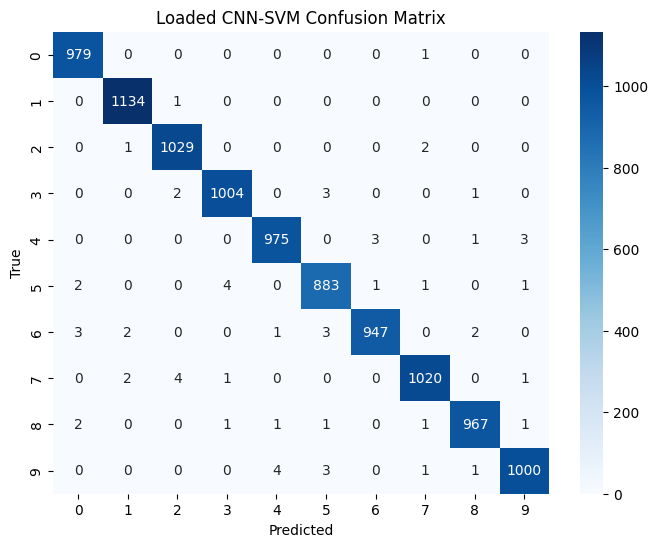

In [35]:
X_test_features_all = loaded_feature_extractor.predict(X_test_cnn, verbose=0)
y_test_pred_loaded = loaded_svm.predict(X_test_features_all)

loaded_results = evaluate_model(y_test, y_test_pred_loaded, "Loaded CNN-SVM")
plot_conf_matrix(y_test, y_test_pred_loaded, "Loaded CNN-SVM Confusion Matrix")

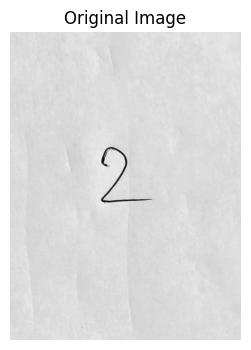

In [37]:
from PIL import Image
import cv2

image_path = "Two.jpg"

img = Image.open(image_path).convert("L")
img_array = np.array(img)

plt.figure(figsize=(4,4))
plt.imshow(img_array, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

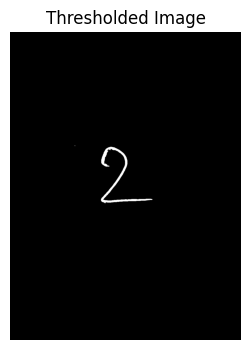

In [38]:
# Blur a little to reduce noise
blurred = cv2.GaussianBlur(img_array, (5,5), 0)

# Binary inverse threshold
_, thresh = cv2.threshold(blurred, 150, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=(4,4))
plt.imshow(thresh, cmap="gray")
plt.title("Thresholded Image")
plt.axis("off")
plt.show()

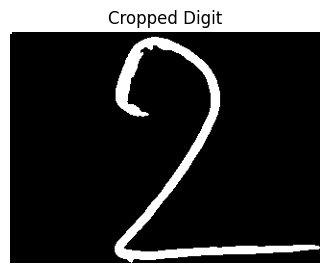

In [39]:
coords = cv2.findNonZero(thresh)

x, y, w, h = cv2.boundingRect(coords)
cropped = thresh[y:y+h, x:x+w]

plt.figure(figsize=(4,4))
plt.imshow(cropped, cmap="gray")
plt.title("Cropped Digit")
plt.axis("off")
plt.show()

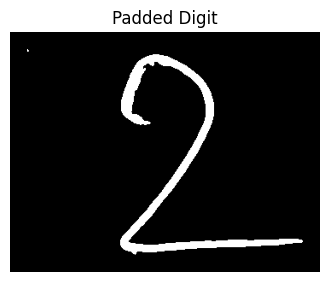

In [40]:
padded = np.pad(cropped, ((20,20), (20,20)), mode='constant', constant_values=0)

plt.figure(figsize=(4,4))
plt.imshow(padded, cmap="gray")
plt.title("Padded Digit")
plt.axis("off")
plt.show()

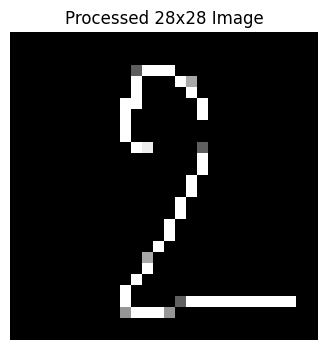

In [41]:
processed = cv2.resize(padded, (28, 28))

plt.figure(figsize=(4,4))
plt.imshow(processed, cmap="gray")
plt.title("Processed 28x28 Image")
plt.axis("off")
plt.show()

In [42]:
processed = processed.astype("float32") / 255.0
img_input = processed.reshape(1, 28, 28, 1)

print("Input shape:", img_input.shape)

Input shape: (1, 28, 28, 1)


In [43]:
img_features = loaded_feature_extractor.predict(img_input, verbose=0)
predicted_digit = loaded_svm.predict(img_features)[0]

print("Predicted digit:", predicted_digit)

Predicted digit: 2
